# Coin Counting and Classification System

## Introduction

Coin counting is an important computer vision application used in automatic cash handling, vending machines, banking systems, and sorting machines.

The goal of this project is to build an image processing pipeline that can detect coins in an image, count them, classify them according to their size, and calculate the total estimated value.

## Objectives

The objectives of this project are:

1. Detect coins from input images.
2. Count the total number of detected coins.
3. Classify coins into small, medium, and large categories based on contour area.
4. Calculate the total estimated value.
5. Evaluate the system by comparing predicted counts with actual counts from the dataset CSV file.
6. Analyze successful results and failure cases.

In [1]:
# ============================================================
# Cell 1: Install and Import Required Libraries
# ============================================================

!pip install kagglehub -q

import os
import cv2
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

plt.rcParams["figure.figsize"] = (12, 8)

print("Libraries imported successfully.")

Libraries imported successfully.


### Analysis

In this cell, the required Python libraries were imported. OpenCV was used for image processing operations, NumPy for numerical calculations, Pandas for reading and handling the CSV file, and Matplotlib for displaying images and visual results.

This cell prepares the notebook environment for the coin counting and classification pipeline.

In [2]:
# ============================================================
# Cell 2: Download Dataset
# ============================================================

path = kagglehub.dataset_download("balabaskar/count-coins-image-dataset")

print("Dataset downloaded at:")
print(path)

100%|██████████| 108M/108M [00:00<00:00, 119MB/s]

Extracting files...


Dataset downloaded at:
/root/.cache/kagglehub/datasets/balabaskar/count-coins-image-dataset/versions/1


### Analysis

In this cell, the coin dataset was downloaded using KaggleHub. The dataset contains coin images and a CSV file that includes the actual number of coins in each image.

This dataset will be used to test and evaluate the performance of the coin detection system.

In [3]:
# ============================================================
# Cell 3: Set Dataset Paths and Load CSV
# ============================================================

base_path = "/root/.cache/kagglehub/datasets/balabaskar/count-coins-image-dataset/versions/1"

csv_path = os.path.join(base_path, "coins_count_values.csv")
image_path = os.path.join(base_path, "coins_images", "coins_images", "all_coins")

coins_df = pd.read_csv(csv_path)

images = [
    img for img in os.listdir(image_path)
    if img.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("CSV Columns:")
print(coins_df.columns)

print("\nFirst rows:")
display(coins_df.head())

print("\nTotal images in all_coins folder:", len(images))
print("Sample image names:", images[:5])

CSV Columns:
Index(['folder', 'image_name', 'coins_count'], dtype='object')

First rows:


,folder,image_name,coins_count
0,all_coins,01207e3d7e.jpg,5
1,all_coins,0140acf6eb.jpg,4
2,all_coins,025c8579f0.jpg,2
3,all_coins,028ca794e7.jpg,4
4,all_coins,02e080206f.jpg,40



Total images in all_coins folder: 215
Sample image names: ['42a0da06b7.jpg', '209529add9.jpg', '898beeed4c.jpg', 'd87fde36bf.jpg', '6bf1678fa3.jpg']


### Analysis

In this cell, the dataset paths were defined. The CSV file was loaded using Pandas, and the image folder path was set to the `all_coins` folder.

The CSV file contains the image names and the actual coin count for each image. This information is important for evaluating the predicted results later.

In [4]:
# ============================================================
# Cell 4: Select Evaluation Images Manually
# 15 images covering easy, medium, and challenging cases
# ============================================================

coins_df = coins_df[coins_df["image_name"].isin(images)].copy()

selected_images = [
    # Easy cases
    "f14da4ee62.jpg",   # actual 4
    "01207e3d7e.jpg",   # actual 5
    "767455e3f9.jpg",   # actual 2
    "2c8f0e58fb.jpg",   # actual 2
    "3a31d6cc15.jpg",   # actual 5

    # Medium cases
    "962d332c3c.jpg",   # actual 6
    "8e89dfa19b.jpg",   # actual 6
    "207092513f.jpg",   # actual 8
    "44e195e1ef.jpg",   # actual 8
    "85e4b42fb6.jpg",   # actual 8
    "b65bf338f7.jpg",   # actual 10
    "f5fd0e7e9b.jpg",   # actual 12

    # Challenging cases
    "0bcb8457d5.jpg",   # actual 11
    "f35a790bd0.jpg",   # actual 14
    "c99b8f0e24.jpg"    # actual 14
]

selected_df = coins_df[coins_df["image_name"].isin(selected_images)].copy()

# Keep same order as selected_images
selected_df["order"] = selected_df["image_name"].apply(lambda x: selected_images.index(x))
selected_df = selected_df.sort_values("order").drop(columns=["order"]).reset_index(drop=True)

print("Selected evaluation images:")
display(selected_df[["image_name", "coins_count"]])

print("\nNumber of selected images:", len(selected_images))

Selected evaluation images:


,image_name,coins_count
0,f14da4ee62.jpg,4
1,01207e3d7e.jpg,5
2,767455e3f9.jpg,2
3,2c8f0e58fb.jpg,2
4,2c8f0e58fb.jpg,2
5,3a31d6cc15.jpg,5
6,962d332c3c.jpg,6
7,8e89dfa19b.jpg,6
8,207092513f.jpg,8
9,44e195e1ef.jpg,8



Number of selected images: 15


###Analysis

In this cell, 15 images were selected for evaluation. The selected images include easy, medium, and challenging cases based on the actual number of coins.

This selection helps test the system on different difficulty levels. Easy images contain fewer coins, while medium and challenging images contain more coins or more complex arrangements.

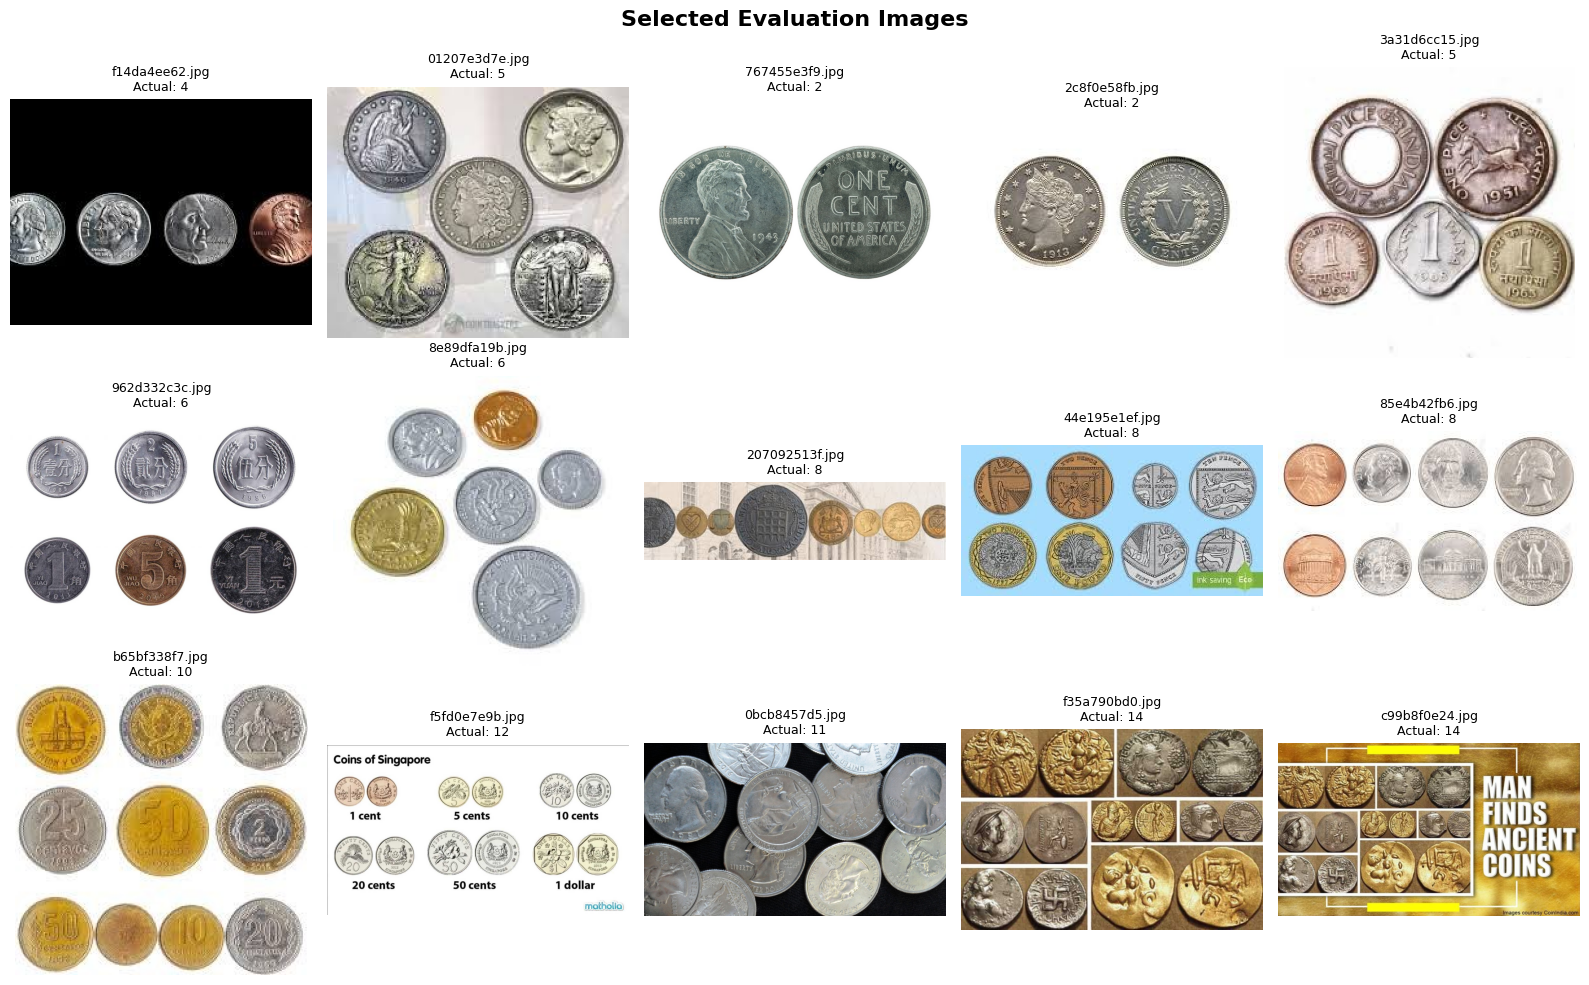

In [5]:
# ============================================================
# Cell 5: Display Selected Evaluation Images
# ============================================================

cols = 5
rows = math.ceil(len(selected_images) / cols)

plt.figure(figsize=(16, 10))

for i, img_name in enumerate(selected_images):
    img_path = os.path.join(image_path, img_name)

    img = cv2.imread(img_path)

    if img is None:
        print("Error reading:", img_name)
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    actual_count = int(
        selected_df.loc[
            selected_df["image_name"] == img_name,
            "coins_count"
        ].values[0]
    )

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"{img_name}\nActual: {actual_count}", fontsize=9)
    plt.axis("off")

plt.suptitle("Selected Evaluation Images", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### Analysis

This cell displays the selected evaluation images before applying any image processing steps. Each image is shown with its actual coin count from the CSV file.

Displaying the original images helps understand the difficulty of the selected dataset, such as lighting variation, coin overlap, background complexity, and the number of coins.

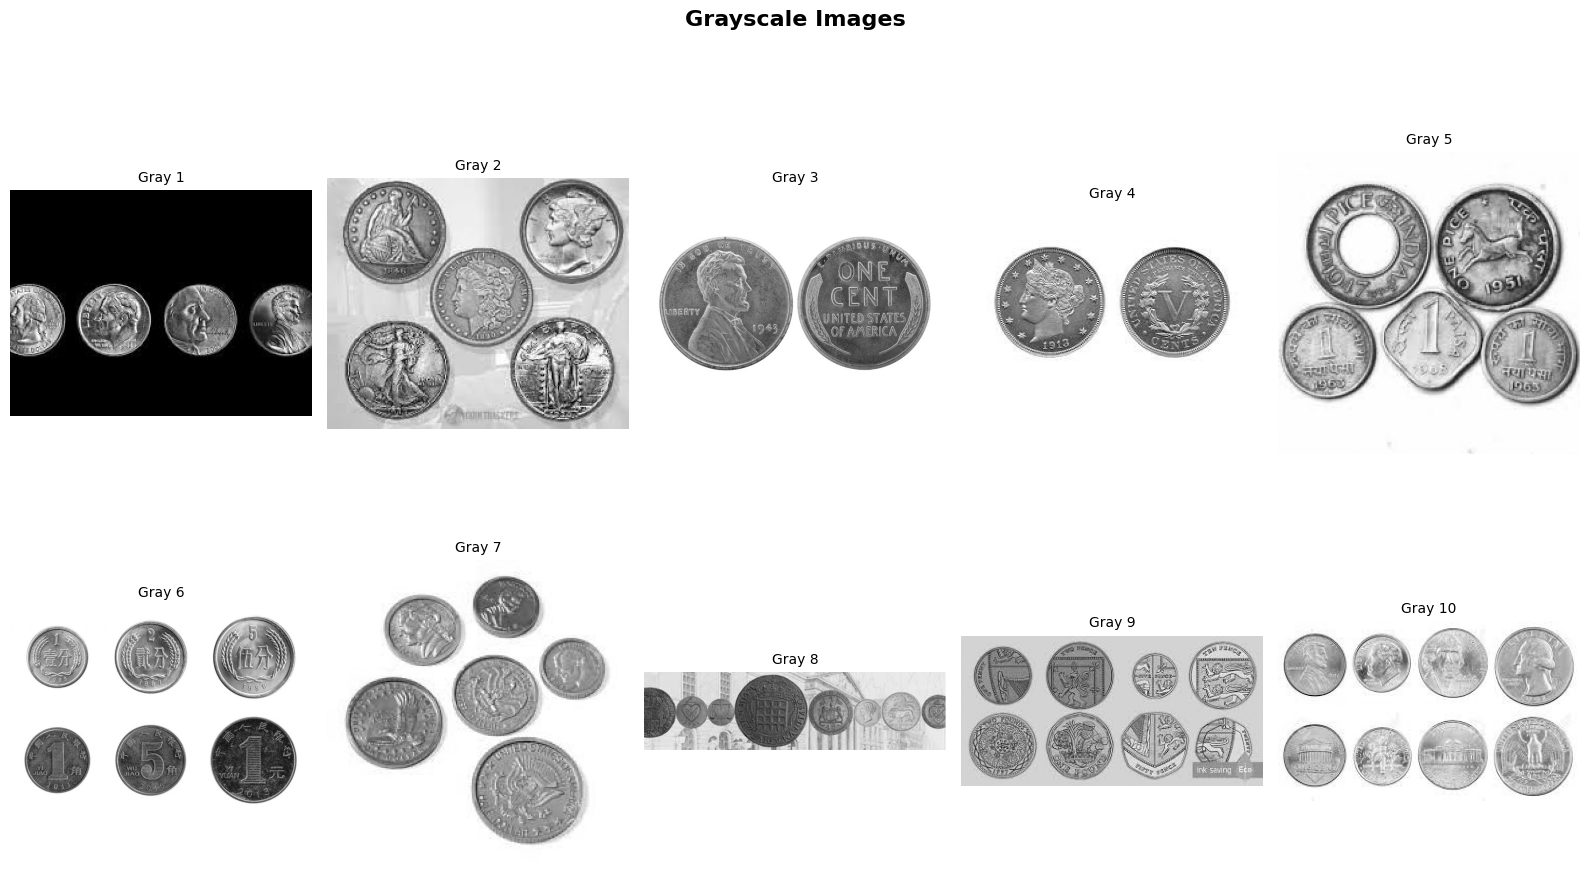

In [6]:
# ============================================================
# Cell 6: Grayscale Conversion
# ============================================================

plt.figure(figsize=(16, 10))

for i, img_name in enumerate(selected_images[:10]):
    img_path = os.path.join(image_path, img_name)

    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    plt.subplot(2, 5, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(f"Gray {i+1}", fontsize=10)
    plt.axis("off")

plt.suptitle("Grayscale Images", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

###Analysis

In this step, the selected images were converted from colored images to grayscale images.

Grayscale conversion reduces the image from three color channels to one intensity channel. This simplifies the processing because most thresholding and contour detection techniques work better on grayscale images.

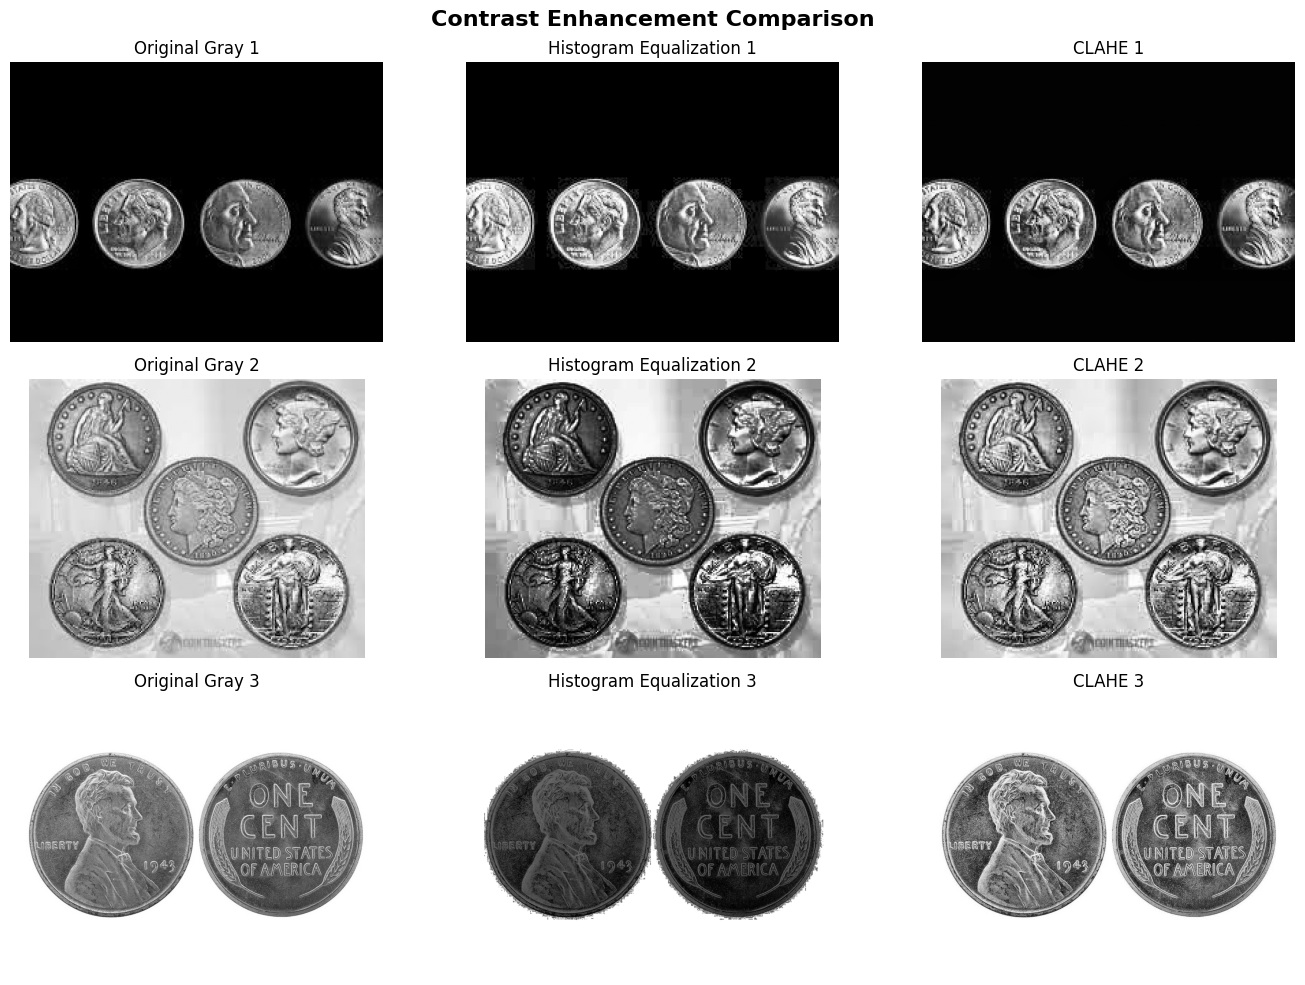

In [7]:
# ============================================================
# Cell 7: Contrast Enhancement Comparison
# Grayscale vs Histogram Equalization vs CLAHE
# ============================================================

comparison_images = selected_images[:3]

plt.figure(figsize=(14, 10))
plt.suptitle("Contrast Enhancement Comparison", fontsize=16, fontweight="bold")

for i, img_name in enumerate(comparison_images):
    img_path = os.path.join(image_path, img_name)

    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hist_eq = cv2.equalizeHist(gray)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    clahe_img = clahe.apply(gray)

    plt.subplot(3, 3, 3*i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(f"Original Gray {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 2)
    plt.imshow(hist_eq, cmap="gray")
    plt.title(f"Histogram Equalization {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 3)
    plt.imshow(clahe_img, cmap="gray")
    plt.title(f"CLAHE {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Analysis

This cell compares different contrast enhancement techniques: the original grayscale image, histogram equalization, and CLAHE.

Histogram equalization improves the overall contrast of the image, but it may increase noise in some regions. CLAHE improves contrast locally in small regions, making it more suitable for images with uneven lighting.

For this project, CLAHE is useful because it makes coin boundaries clearer before thresholding.

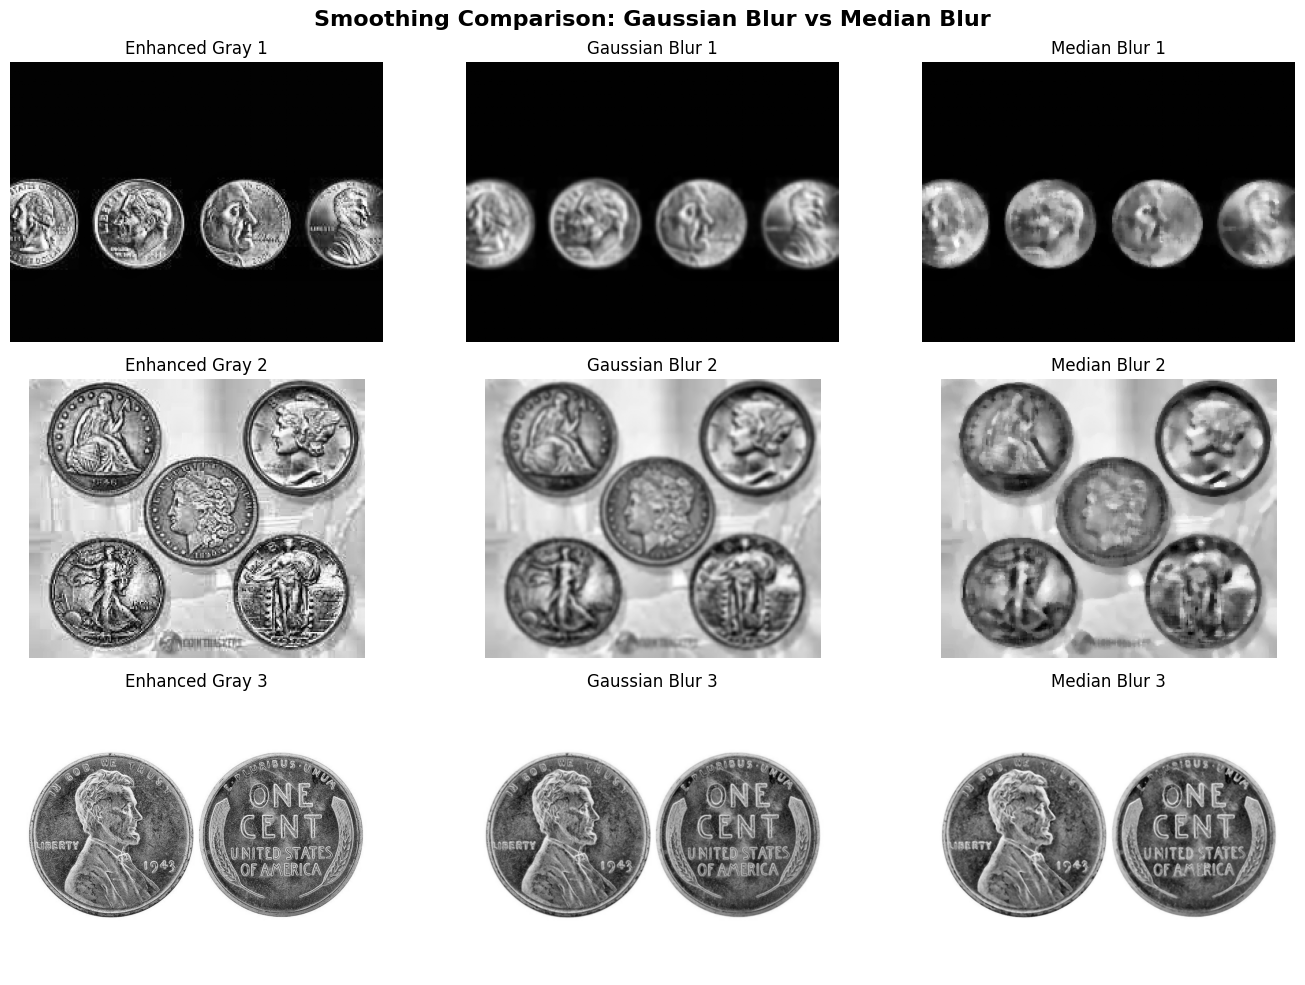

In [8]:
# ============================================================
# Cell 8: Smoothing Comparison
# Gaussian Blur vs Median Blur
# ============================================================

comparison_images = selected_images[:3]

plt.figure(figsize=(14, 10))
plt.suptitle("Smoothing Comparison: Gaussian Blur vs Median Blur", fontsize=16, fontweight="bold")

for i, img_name in enumerate(comparison_images):
    img_path = os.path.join(image_path, img_name)

    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    gaussian = cv2.GaussianBlur(enhanced, (5, 5), 0)
    median = cv2.medianBlur(enhanced, 5)

    plt.subplot(3, 3, 3*i + 1)
    plt.imshow(enhanced, cmap="gray")
    plt.title(f"Enhanced Gray {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 2)
    plt.imshow(gaussian, cmap="gray")
    plt.title(f"Gaussian Blur {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 3)
    plt.imshow(median, cmap="gray")
    plt.title(f"Median Blur {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Analysis

This cell compares Gaussian blur and median blur.

Gaussian blur reduces general noise by averaging neighboring pixels, but it may slightly blur coin edges. Median blur removes small noise while preserving sharp edges better.

Since coin boundaries are important for contour detection, median blur is more suitable for this project.

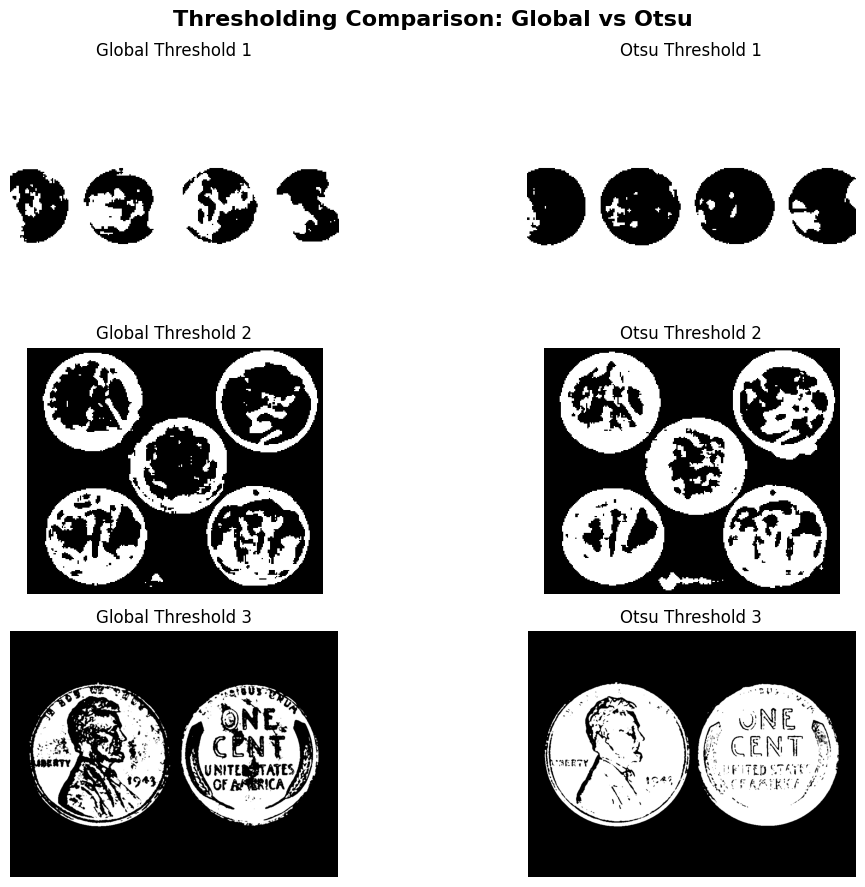

In [9]:
# ============================================================
# Cell 9: Thresholding Comparison
# Global Thresholding vs Otsu Thresholding
# ============================================================

comparison_images = selected_images[:3]

plt.figure(figsize=(12, 9))
plt.suptitle("Thresholding Comparison: Global vs Otsu", fontsize=16, fontweight="bold")

for i, img_name in enumerate(comparison_images):
    img_path = os.path.join(image_path, img_name)

    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    blur = cv2.medianBlur(enhanced, 5)

    _, global_th = cv2.threshold(
        blur, 127, 255,
        cv2.THRESH_BINARY_INV
    )

    _, otsu_th = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(global_th, cmap="gray")
    plt.title(f"Global Threshold {i+1}")
    plt.axis("off")

    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(otsu_th, cmap="gray")
    plt.title(f"Otsu Threshold {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

###Analysis

This cell compares global thresholding and Otsu thresholding.

Global thresholding uses a fixed threshold value for all images, so it may fail when lighting conditions change. Otsu thresholding automatically calculates the best threshold value based on the image histogram.

Otsu thresholding is more flexible for this dataset because the images have different brightness levels and backgrounds.

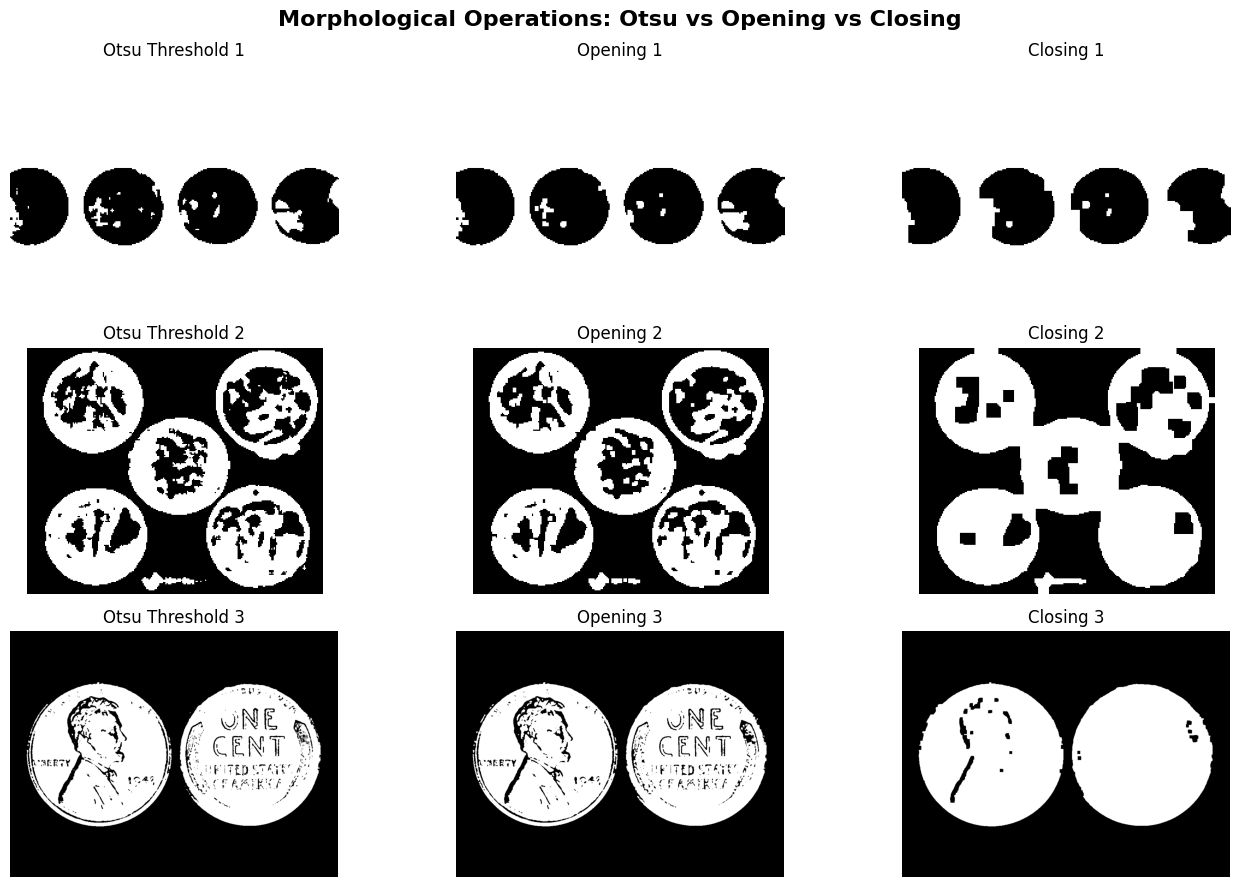

In [10]:
# ============================================================
# Cell 10: Morphological Operations
# Otsu Thresholding vs Opening vs Closing
# ============================================================

morphology_images = selected_images[:3]

plt.figure(figsize=(14, 9))
plt.suptitle("Morphological Operations: Otsu vs Opening vs Closing", fontsize=16, fontweight="bold")

for i, img_name in enumerate(morphology_images):

    img = cv2.imread(os.path.join(image_path, img_name))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    blur = cv2.medianBlur(enhanced, 5)

    _, th_otsu = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    kernel3 = np.ones((3, 3), np.uint8)
    kernel5 = np.ones((5, 5), np.uint8)

    opening = cv2.morphologyEx(th_otsu, cv2.MORPH_OPEN, kernel3, iterations=1)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel5, iterations=2)

    plt.subplot(3, 3, 3*i + 1)
    plt.imshow(th_otsu, cmap="gray")
    plt.title(f"Otsu Threshold {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 2)
    plt.imshow(opening, cmap="gray")
    plt.title(f"Opening {i+1}")
    plt.axis("off")

    plt.subplot(3, 3, 3*i + 3)
    plt.imshow(closing, cmap="gray")
    plt.title(f"Closing {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Analysis

This cell applies morphological operations after thresholding.

Opening is used to remove small noise from the binary image. Closing is used to fill small gaps inside coin regions and make the coin shapes more connected.

These operations improve the binary image before detecting contours. However, morphology alone may not fully separate coins that are touching or overlapping.

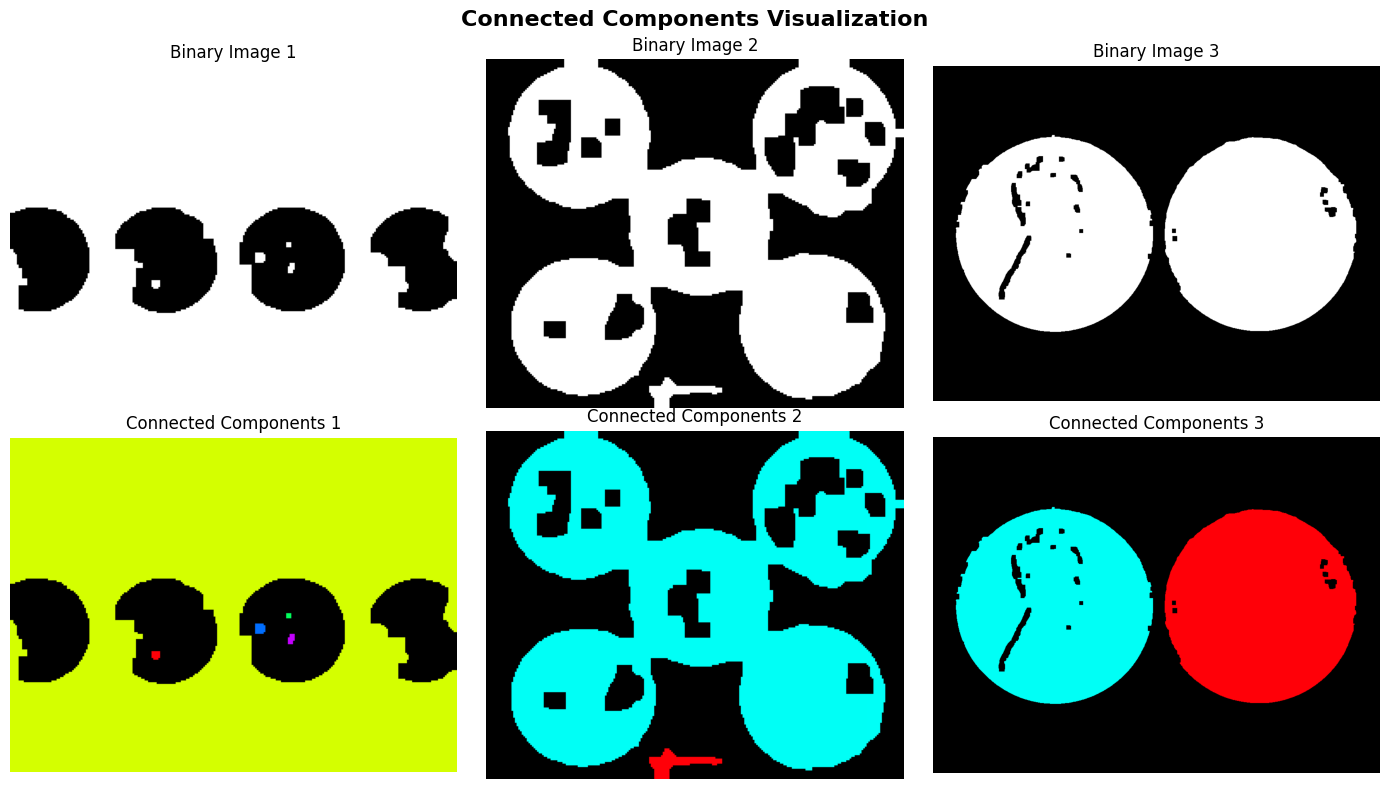

In [11]:
# ============================================================
# Cell 11: Connected Components Visualization
# ============================================================

component_images = selected_images[:3]

plt.figure(figsize=(14, 8))
plt.suptitle("Connected Components Visualization", fontsize=16, fontweight="bold")

for i, img_name in enumerate(component_images):

    img = cv2.imread(os.path.join(image_path, img_name))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    blur = cv2.medianBlur(enhanced, 5)

    _, th = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    kernel3 = np.ones((3, 3), np.uint8)
    kernel5 = np.ones((5, 5), np.uint8)

    opening = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel3, iterations=1)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel5, iterations=2)

    num_labels, labels = cv2.connectedComponents(closing)

    label_hue = np.uint8(179 * labels / np.max(labels))
    blank_ch = 255 * np.ones_like(label_hue)
    colored_components = cv2.merge([label_hue, blank_ch, blank_ch])
    colored_components = cv2.cvtColor(colored_components, cv2.COLOR_HSV2RGB)
    colored_components[label_hue == 0] = 0

    plt.subplot(2, 3, i + 1)
    plt.imshow(closing, cmap="gray")
    plt.title(f"Binary Image {i+1}")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(colored_components)
    plt.title(f"Connected Components {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

###Analysis

This cell visualizes connected components in the binary image.

Connected components help show how separated regions appear after thresholding and morphological operations. Ideally, each coin should appear as one separate connected component.

If multiple coins are touching, they may appear as one merged component, which can reduce the accuracy of the detection step.

In [12]:
# ============================================================
# Cell 12: Strong Multi-Method Contour-Based Coin Detection Pipeline
# ============================================================

def process_coin_image(img_path):
    """
    Strong coin detection pipeline:
    1. Read image
    2. Convert to grayscale
    3. Improve contrast using CLAHE
    4. Generate multiple binary candidates
    5. Detect contours for each candidate
    6. Choose the best candidate using contour quality score
    7. Count and classify coins
    """

    img = cv2.imread(img_path)

    if img is None:
        print("Error reading:", img_path)
        return None, 0, 0, []

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize large images to make parameters more stable
    h0, w0 = gray.shape
    scale = 1.0

    max_size = 700
    if max(h0, w0) > max_size:
        scale = max_size / max(h0, w0)
        img_rgb = cv2.resize(img_rgb, None, fx=scale, fy=scale)
        gray = cv2.resize(gray, None, fx=scale, fy=scale)

    h, w = gray.shape
    image_area = h * w

    # Contrast enhancement
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Smoothing
    median = cv2.medianBlur(enhanced, 5)
    gaussian = cv2.GaussianBlur(enhanced, (5, 5), 0)

    kernel3 = np.ones((3, 3), np.uint8)
    kernel5 = np.ones((5, 5), np.uint8)

    candidates = []

    # Candidate 1: Otsu Inverse
    _, otsu_inv = cv2.threshold(
        median, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    candidates.append(("Otsu Inverse", otsu_inv))

    # Candidate 2: Otsu Binary
    _, otsu_bin = cv2.threshold(
        median, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    candidates.append(("Otsu Binary", otsu_bin))

    # Candidate 3: Adaptive Inverse
    adaptive_inv = cv2.adaptiveThreshold(
        gaussian,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        51,
        5
    )
    candidates.append(("Adaptive Inverse", adaptive_inv))

    # Candidate 4: Canny + Closing
    edges = cv2.Canny(median, 50, 150)
    edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel5, iterations=2)
    edges_filled = cv2.dilate(edges_closed, kernel3, iterations=1)
    candidates.append(("Canny Edges", edges_filled))

    def clean_and_get_contours(binary_img):
        opening = cv2.morphologyEx(
            binary_img,
            cv2.MORPH_OPEN,
            kernel3,
            iterations=1
        )

        closing = cv2.morphologyEx(
            opening,
            cv2.MORPH_CLOSE,
            kernel5,
            iterations=2
        )

        contours, _ = cv2.findContours(
            closing,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        min_area = image_area * 0.00025
        max_area = image_area * 0.30

        valid = []

        for cnt in contours:
            area = cv2.contourArea(cnt)

            if area < min_area or area > max_area:
                continue

            perimeter = cv2.arcLength(cnt, True)

            if perimeter == 0:
                continue

            circularity = 4 * np.pi * area / (perimeter ** 2)

            x, y, bw, bh = cv2.boundingRect(cnt)
            aspect_ratio = bw / float(bh)

            (cx, cy), radius = cv2.minEnclosingCircle(cnt)

            if (
                circularity >= 0.18 and
                radius >= 4 and
                0.35 <= aspect_ratio <= 2.8
            ):
                valid.append(cnt)

        return valid, closing

    best_name = None
    best_binary = None
    best_contours = []
    best_score = -1

    for name, candidate in candidates:

        valid, cleaned = clean_and_get_contours(candidate)

        count = len(valid)
        fg_ratio = np.sum(cleaned == 255) / cleaned.size

        if count == 0:
            score = -100
        else:
            score = count

            if fg_ratio < 0.01:
                score -= 20

            if fg_ratio > 0.65:
                score -= 20

            if count > 25:
                score -= 15

        if score > best_score:
            best_score = score
            best_name = name
            best_binary = cleaned
            best_contours = valid

    valid_coins = best_contours

    output = img_rgb.copy()

    areas = [cv2.contourArea(cnt) for cnt in valid_coins]

    value_map = {
        "Small": 1,
        "Medium": 5,
        "Large": 10
    }

    total_value = 0

    if len(areas) > 0:
        small_limit = np.percentile(areas, 33)
        medium_limit = np.percentile(areas, 66)
    else:
        small_limit = 0
        medium_limit = 0

    for cnt in valid_coins:
        area = cv2.contourArea(cnt)

        if area <= small_limit:
            label = "Small"
        elif area <= medium_limit:
            label = "Medium"
        else:
            label = "Large"

        total_value += value_map[label]

        (x, y), radius = cv2.minEnclosingCircle(cnt)
        center = (int(x), int(y))
        radius = int(radius)

        cv2.circle(output, center, radius, (0, 255, 0), 2)

        cv2.putText(
            output,
            label,
            (center[0] - 22, center[1]),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.35,
            (255, 0, 0),
            1
        )

    coin_count = len(valid_coins)

    cv2.putText(
    output,
    f"Count: {coin_count} | Total Value: {total_value}",
    (10, 18),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.35,
    (255, 0, 0),
    1
)

    return output, coin_count, total_value, valid_coins

###Analysis

This cell contains the main coin detection pipeline.

The system reads the image, converts it to grayscale, improves contrast using CLAHE, applies smoothing, and generates multiple binary image candidates using Otsu thresholding, adaptive thresholding, and edge detection.

Contours are then extracted from each candidate image. The system filters the detected regions using area, circularity, radius, and aspect ratio to keep coin-like objects only.

Finally, the detected coins are classified into small, medium, and large categories based on contour area, and the total value is calculated.

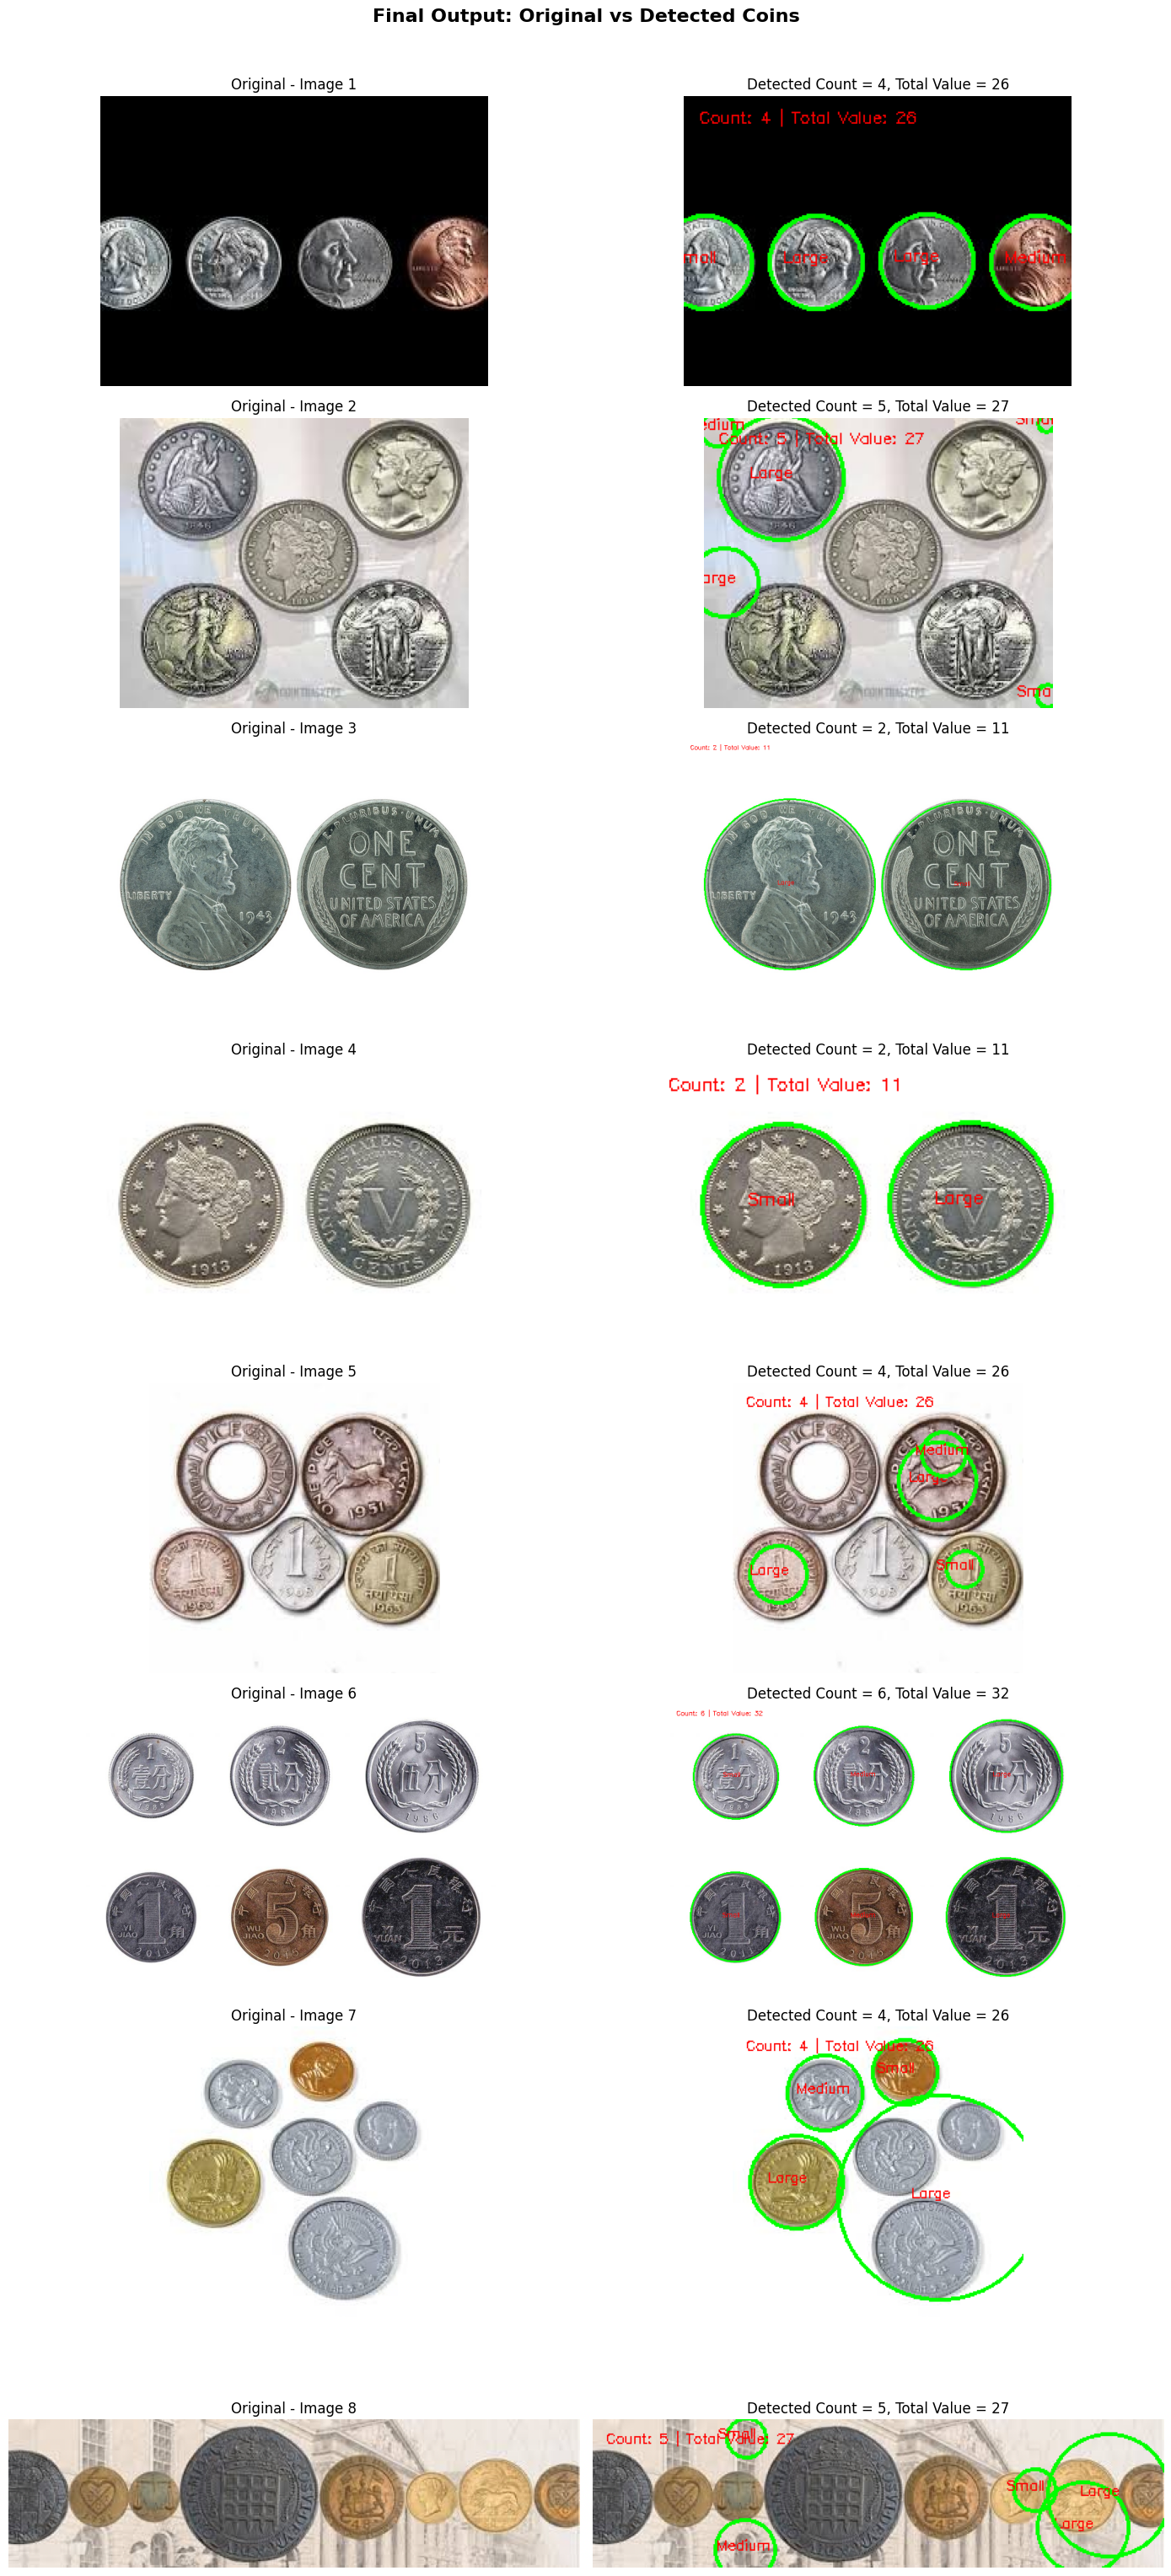

In [13]:
# ============================================================
# Cell 13: Final Output Display
# Original Image vs Detected Coins
# ============================================================

display_images = selected_images[:8]

rows = len(display_images)
cols = 2

plt.figure(figsize=(14, 4 * rows))
plt.suptitle("Final Output: Original vs Detected Coins", fontsize=16, fontweight="bold")

for i, img_name in enumerate(display_images):

    img_path = os.path.join(image_path, img_name)

    original = cv2.imread(img_path)

    if original is None:
        print("Error reading:", img_name)
        continue

    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    output, count, total_value, valid_coins = process_coin_image(img_path)

    # Original image
    plt.subplot(rows, cols, 2*i + 1)
    plt.imshow(original_rgb)
    plt.title(f"Original - Image {i+1}")
    plt.axis("off")

    # Final detected output
    plt.subplot(rows, cols, 2*i + 2)
    plt.imshow(output)
    plt.title(f"Detected Count = {count}, Total Value = {total_value}")
    plt.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Analysis

This cell displays the final output of the system.

For each selected image, the original image is shown next to the processed image. In the processed image, detected coins are circled and labeled according to their estimated size category.

The predicted coin count and total estimated value are also displayed on the image.

In [14]:
# ============================================================
# Cell 14: Evaluation Table
# Actual Count vs Predicted Count and Accuracy
# ============================================================

evaluation_results = []

for img_name in selected_images:

    img_path = os.path.join(image_path, img_name)

    output, predicted_count, total_value, valid_coins = process_coin_image(img_path)

    actual_count = int(
        selected_df.loc[
            selected_df["image_name"] == img_name,
            "coins_count"
        ].values[0]
    )

    error = abs(actual_count - predicted_count)

    accuracy = (1 - error / actual_count) * 100
    accuracy = max(0, accuracy)

    evaluation_results.append({
        "Image": img_name,
        "Actual Count": actual_count,
        "Predicted Count": predicted_count,
        "Absolute Error": error,
        "Accuracy (%)": round(accuracy, 2),
        "Total Value": total_value
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

average_accuracy = evaluation_df["Accuracy (%)"].mean()

print("Average Accuracy:", round(average_accuracy, 2), "%")

,Image,Actual Count,Predicted Count,Absolute Error,Accuracy (%),Total Value
0,f14da4ee62.jpg,4,4,0,100.00,26
1,01207e3d7e.jpg,5,5,0,100.00,27
2,767455e3f9.jpg,2,2,0,100.00,11
3,2c8f0e58fb.jpg,2,2,0,100.00,11
4,3a31d6cc15.jpg,5,4,1,80.00,26
5,962d332c3c.jpg,6,6,0,100.00,32
6,8e89dfa19b.jpg,6,4,2,66.67,26
7,207092513f.jpg,8,5,3,62.50,27
8,44e195e1ef.jpg,8,5,3,62.50,27
9,85e4b42fb6.jpg,8,4,4,50.00,26


Average Accuracy: 74.06 %


###Analysis

This cell evaluates the system performance.

The predicted coin count is compared with the actual coin count from the CSV file. The absolute error is calculated for each image, and the accuracy percentage is computed based on the difference between the actual and predicted counts.

The average accuracy summarizes the overall performance of the system on the selected evaluation images.

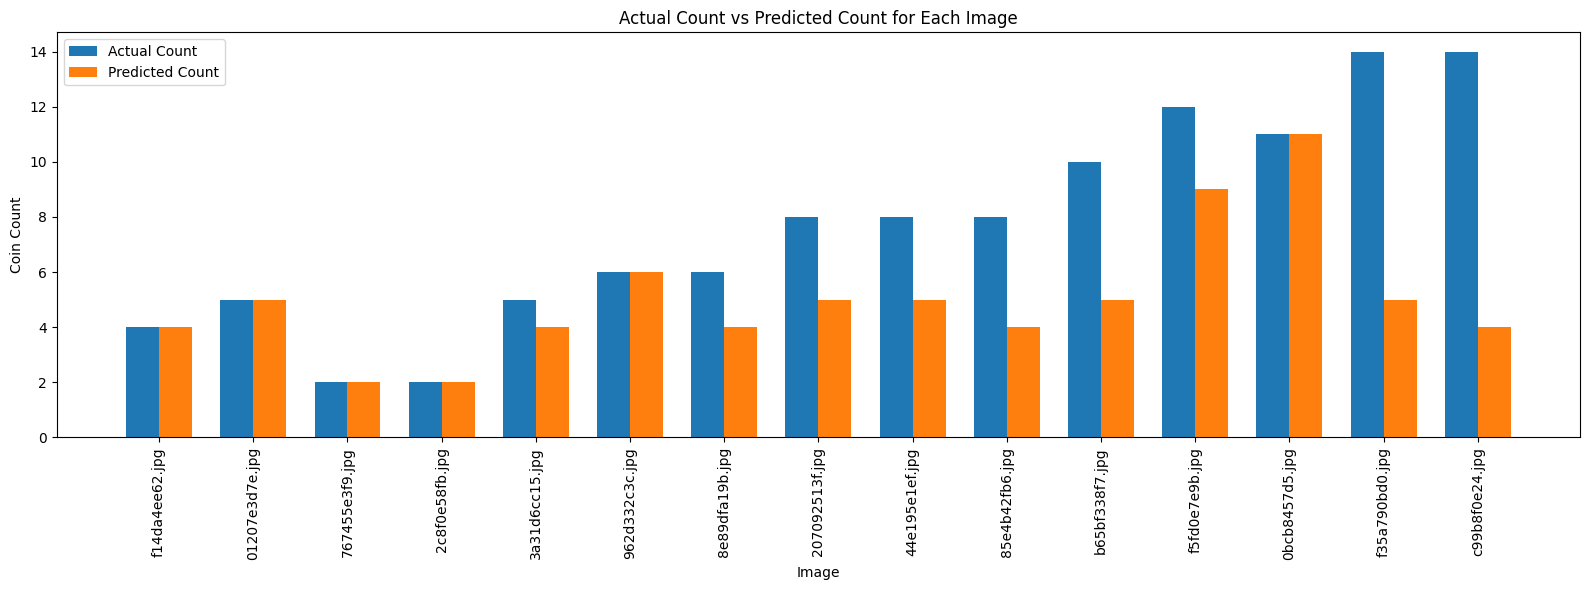

In [15]:
# ============================================================
# Cell 14.1: Visualization - Actual Count vs Predicted Count
# ============================================================

x = np.arange(len(evaluation_df))
width = 0.35

plt.figure(figsize=(16, 6))

plt.bar(x - width/2, evaluation_df["Actual Count"], width, label="Actual Count")
plt.bar(x + width/2, evaluation_df["Predicted Count"], width, label="Predicted Count")

plt.xticks(x, evaluation_df["Image"], rotation=90)
plt.xlabel("Image")
plt.ylabel("Coin Count")
plt.title("Actual Count vs Predicted Count for Each Image")
plt.legend()

plt.tight_layout()
plt.show()

### Actual vs Predicted Count Analysis

This chart compares the actual number of coins with the predicted number of coins for each evaluation image.

When the two bars are close in height, the system performed well on that image. Large differences between the bars indicate counting errors, usually caused by overlapping coins, cropped coins, shadows, or complex backgrounds.

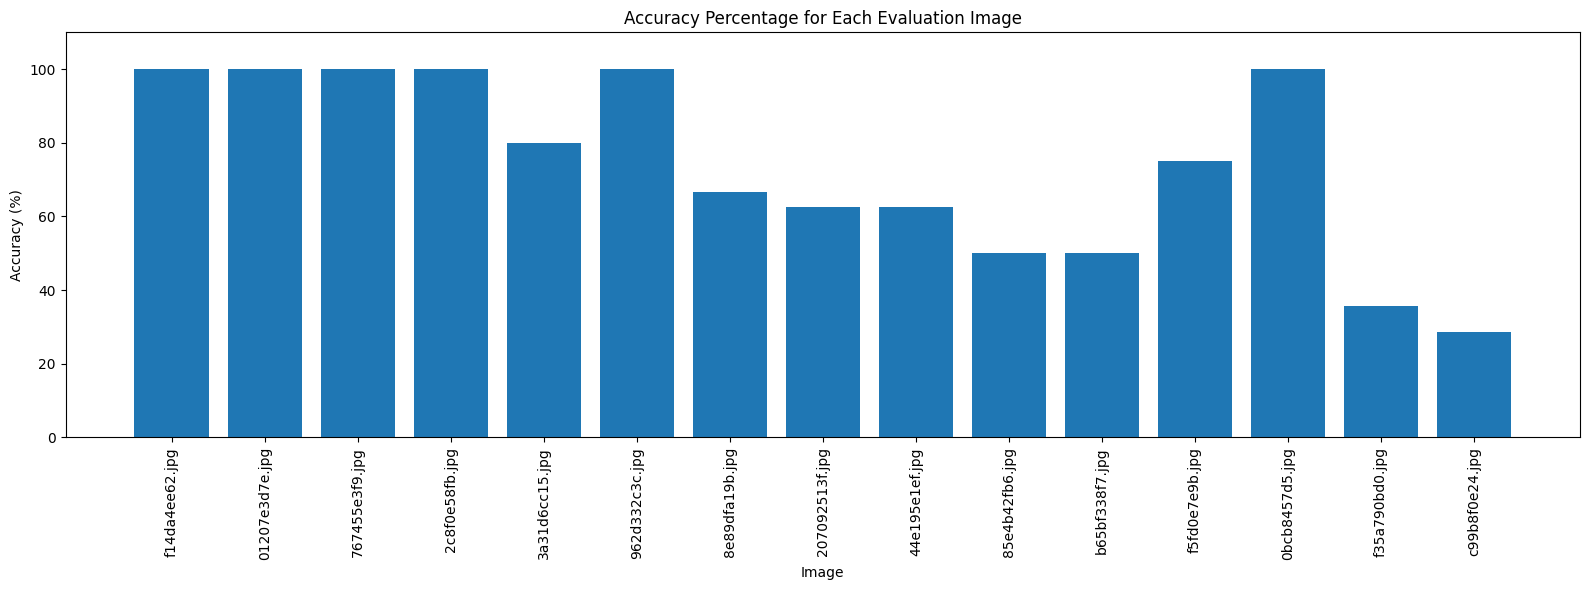

In [16]:
# ============================================================
# Cell 14.2: Visualization - Accuracy Percentage per Image
# ============================================================

plt.figure(figsize=(16, 6))

plt.bar(evaluation_df["Image"], evaluation_df["Accuracy (%)"])

plt.xticks(rotation=90)
plt.xlabel("Image")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Percentage for Each Evaluation Image")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

### Accuracy Visualization Analysis

This chart shows the accuracy percentage for each evaluation image.

Images with high accuracy were detected successfully, while images with low accuracy were more difficult for the system. Low accuracy usually appears when coins are touching, overlapping, cropped, or placed on complex backgrounds.

In [17]:
# ============================================================
# Visualization 6: Summary Statistics
# ============================================================

mean_accuracy = evaluation_df["Accuracy (%)"].mean()
best_accuracy = evaluation_df["Accuracy (%)"].max()
worst_accuracy = evaluation_df["Accuracy (%)"].min()
mean_error = evaluation_df["Absolute Error"].mean()

print("========== Project Summary ==========")
print("Number of Evaluation Images:", len(evaluation_df))
print("Average Accuracy:", round(mean_accuracy, 2), "%")
print("Best Accuracy:", round(best_accuracy, 2), "%")
print("Worst Accuracy:", round(worst_accuracy, 2), "%")
print("Average Absolute Error:", round(mean_error, 2))

========== Project Summary ==========
Number of Evaluation Images: 15
Average Accuracy: 74.06 %
Best Accuracy: 100.0 %
Worst Accuracy: 28.57 %
Average Absolute Error: 2.67


### Summary Statistics Analysis

This summary provides an overall view of the system performance.

The average accuracy represents the general counting performance across all selected evaluation images. The best and worst accuracy values show the range of system performance, while the average absolute error shows the average difference between the actual and predicted coin counts.

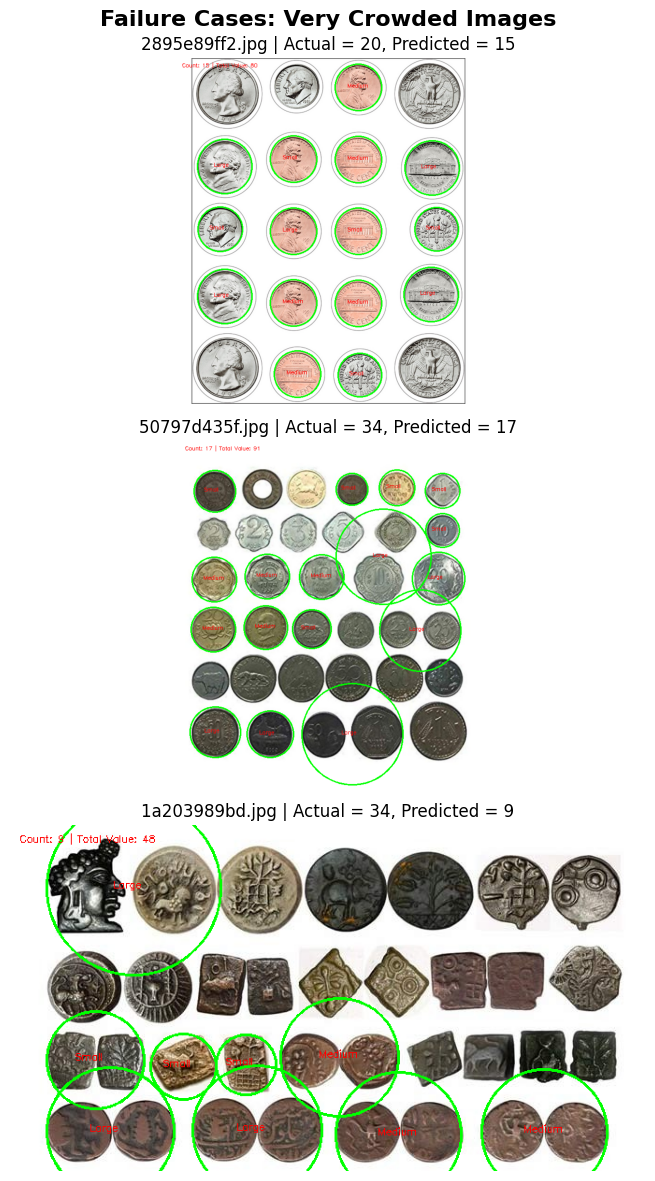

In [18]:
# ============================================================
# Cell 15: Failure Cases
# Very crowded images
# ============================================================

failure_cases = coins_df[
    coins_df["coins_count"] >= 20
].sample(3, random_state=7)["image_name"].tolist()

plt.figure(figsize=(12, 12))
plt.suptitle("Failure Cases: Very Crowded Images", fontsize=16, fontweight="bold")

for i, img_name in enumerate(failure_cases):

    img_path = os.path.join(image_path, img_name)

    output, predicted_count, total_value, valid_coins = process_coin_image(img_path)

    actual_count = int(
        coins_df.loc[
            coins_df["image_name"] == img_name,
            "coins_count"
        ].values[0]
    )

    plt.subplot(3, 1, i + 1)
    plt.imshow(output)
    plt.title(f"{img_name} | Actual = {actual_count}, Predicted = {predicted_count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

###Analysis

This cell displays failure cases where the system struggled.

These images are more difficult because they may contain many coins, touching coins, overlapping coins, shadows, cropped coins, or complex backgrounds.

Failure cases are important because they show the limitations of the current method and help explain where future improvements are needed.

## Failure Cases Analysis

The failure cases show the limitations of the contour-based detection method. In crowded images, many coins are touching or overlapping, so several coins may merge into one connected component. This causes the predicted count to be lower than the actual count.

Some images also contain shadows, cropped coins, dark coins, or complex backgrounds. These conditions make thresholding and contour detection more difficult because some background regions may appear similar to coins.

The system performs better when coins are clearly separated, circular, and placed on a simple background. More advanced segmentation methods such as watershed could improve the results for overlapping coins.

## Challenges and Limitations

The main challenge in this project was separating coins that are touching or overlapping. When coins are very close to each other, thresholding and morphological operations may merge them into one connected region.

Another limitation was the variation in lighting and background color between images. Some images had shadows or low contrast, which made it harder to separate the coins from the background.

The classification step was based on contour area. This method works when coin sizes are clearly different, but it may be less accurate when coins have similar sizes or when the detected contour is incomplete.

The system also struggled with very crowded images because contour-based detection cannot always separate overlapping coins correctly.

## Conclusion

In this project, a coin counting and classification system was implemented using Python, OpenCV, and NumPy.

The system followed a complete image processing pipeline including grayscale conversion, contrast enhancement, smoothing, thresholding, morphological operations, connected components, contour detection, and classification based on coin size.

The system successfully detected and counted coins in several images, especially when the coins were separated and the background was clear. The evaluation table showed the difference between the actual coin count and the predicted coin count for the selected test images.

The main difficulties appeared in crowded images, overlapping coins, cropped coins, shadows, and complex backgrounds. Future improvements could include stronger watershed segmentation, better parameter tuning, and a graphical user interface that allows users to upload and process images easily.

# Bonus: Graphical User Interface (GUI)

This section provides a simple graphical user interface that allows the user to upload a coin image, process it using the implemented pipeline, display the original image, display the final detected result, and show the predicted count and total estimated value.

In [19]:
# ============================================================
# GUI Cell 1: Import GUI Libraries
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image
import io
import tempfile

print("GUI libraries loaded successfully.")

GUI libraries loaded successfully.


In [20]:
# ============================================================
# GUI Cell 2: Coin Counting GUI
# Upload Image -> Process -> Display Results
# ============================================================

# Upload button
upload_button = widgets.FileUpload(
    accept=".jpg,.jpeg,.png",
    multiple=False,
    description="Upload Image"
)

# Process button
process_button = widgets.Button(
    description="Process Image",
    button_style="success"
)

# Output display areas
original_output = widgets.Output()
result_output = widgets.Output()
text_output = widgets.Output()

uploaded_image_path = None


def handle_upload(change):
    """
    This function runs when the user uploads an image.
    It saves the uploaded image temporarily and displays the original image.
    """
    global uploaded_image_path

    original_output.clear_output()
    result_output.clear_output()
    text_output.clear_output()

    if len(upload_button.value) == 0:
        return

    uploaded_file = list(upload_button.value.values())[0]
    image_bytes = uploaded_file["content"]

    # Save uploaded image temporarily
    temp_file = tempfile.NamedTemporaryFile(delete=False, suffix=".jpg")
    temp_file.write(image_bytes)
    temp_file.close()

    uploaded_image_path = temp_file.name

    # Display original image
    image = Image.open(io.BytesIO(image_bytes))

    with original_output:
        plt.figure(figsize=(5, 5))
        plt.imshow(image)
        plt.title("Original Uploaded Image")
        plt.axis("off")
        plt.show()

    with text_output:
        print("Image uploaded successfully. Click 'Process Image' to run the pipeline.")


def process_uploaded_image(button):
    """
    This function runs the full coin detection pipeline on the uploaded image.
    It displays the final output and numerical results.
    """
    result_output.clear_output()
    text_output.clear_output()

    if uploaded_image_path is None:
        with text_output:
            print("Please upload an image first.")
        return

    output, predicted_count, total_value, valid_coins = process_coin_image(uploaded_image_path)

    with result_output:
        plt.figure(figsize=(5, 5))
        plt.imshow(output)
        plt.title("Final Detected Result")
        plt.axis("off")
        plt.show()

    with text_output:
        print("========== GUI Results ==========")
        print("Predicted Coin Count:", predicted_count)
        print("Estimated Total Value:", total_value)
        print("Detected Coin Regions:", len(valid_coins))


# Connect buttons to functions
upload_button.observe(handle_upload, names="value")
process_button.on_click(process_uploaded_image)

# GUI Layout
gui_layout = widgets.VBox([
    widgets.HTML("<h2>Coin Counting and Classification GUI</h2>"),
    widgets.HTML("<p>Upload a coin image, then click the process button to detect and count coins.</p>"),
    upload_button,
    process_button,

    widgets.HBox([
        widgets.VBox([
            widgets.HTML("<h3>Original Image</h3>"),
            original_output
        ], layout=widgets.Layout(width="50%")),

        widgets.VBox([
            widgets.HTML("<h3>Final Result</h3>"),
            result_output
        ], layout=widgets.Layout(width="50%"))
    ], layout=widgets.Layout(width="100%", justify_content="space-between")),

    widgets.HTML("<h3>Results</h3>"),
    text_output
])

display(gui_layout)